# A toy chance-constrained problem

This notebook accompanies the toy example of the chance-constrained programming slides (source: J. Linderoth, [IE 495, lecture 22](https://jlinderoth.github.io/classes/ie495/lecture22.pdf)):
$$
\min_x\ x_1 + x_2 \quad \text{s.t.} \quad \xi_1 x_1 + x_2 \geq 7, \quad \xi_2 x_1 + x_2 \geq 4, \quad x_1, x_2 \geq 0,
$$
where $(\xi_1, \xi_2)$ takes four values:

| Scenario $s$ | $(\xi_1, \xi_2)$ | $p_s$ |
|:---:|:---:|:---:|
| 1 | $(1, 1)$     | 0.1 |
| 2 | $(2, 5/9)$   | 0.4 |
| 3 | $(3, 7/9)$   | 0.4 |
| 4 | $(4, 1/3)$   | 0.1 |

With the risk level $\alpha \in [0.1, 0.2)$, the joint chance constraint
$$
P\left[\xi_1 x_1 + x_2 \geq 7,\ \xi_2 x_1 + x_2 \geq 4\right] \geq 1 - \alpha
$$
requires both constraints in scenarios 2 and 3, and in scenario 1 or 4.
The notebook draws the feasible set (the figure of the slides), shows that it is not convex, and solves the problem, first by enumeration, then as a mixed-integer linear program.
It ends with the separate chance constraints.

In [1]:
using LinearAlgebra, Printf
using JuMP, HiGHS
using Plots

In [2]:
ξ1 = [1.0, 2.0, 3.0, 4.0]            # coefficient of x₁ in the first constraint
ξ2 = [1.0, 5/9, 7/9, 1/3]            # coefficient of x₁ in the second constraint
ξ2_label = ["1", "5/9", "7/9", "1/3"]
h = [7.0, 4.0]                       # right-hand sides
p = [0.1, 0.4, 0.4, 0.1]             # probabilities
S = length(p)                        # number of scenarios

α = 0.15   # risk level: any α in [0.1, 0.2) gives the same feasible set

0.15

## Feasible set: a union of polyhedra

For a set $\mathcal{S}$ of scenarios, let $P_{\mathcal{S}}$ be the polyhedron where both constraints hold in every scenario of $\mathcal{S}$.
A point satisfies the chance constraint if and only if the scenarios where it satisfies both constraints have a total probability at least $1 - \alpha$.
The feasible set is therefore the union of the polyhedra $P_{\mathcal{S}}$, over the admissible sets $\mathcal{S}$, those with $\sum_{s \in \mathcal{S}} p_s \geq 1 - \alpha$.

As every constraint reads $x_2 \geq h - \xi x_1$, each polyhedron is the region above a convex piecewise-linear function of $x_1$, and the feasible set is the region above the minimum of these functions.

In [3]:
# Admissible sets of scenarios: total probability at least 1 - α
subsets = [[s for s in 1:S if (mask >> (s - 1)) & 1 == 1] for mask in 1:(2^S - 1)]
admissible = filter(scen -> sum(p[scen]) >= 1 - α, subsets)

# Smallest x₂ satisfying both constraints of the scenarios in scen, for a given x₁ ≥ 0
lower(x1, scen) = maximum([0.0; [h[1] - ξ1[s]*x1 for s in scen]; [h[2] - ξ2[s]*x1 for s in scen]])

# Lower boundary of the feasible set
boundary(x1) = minimum(lower(x1, scen) for scen in admissible)

for scen in admissible
    @printf("scenarios %-14s probability %.1f\n", string(scen), sum(p[scen]))
end

scenarios [1, 2, 3]      probability 0.9
scenarios [2, 3, 4]      probability 0.9


scenarios [1, 2, 3, 4]   probability 1.0


Three sets are admissible, but $P_{\{1,2,3,4\}}$ lies in the two others: the feasible set is $P_{\{1,2,3\}} \cup P_{\{2,3,4\}}$.
The next cell draws it with the frontiers of the constraints, colored by scenario, and saves the figure of the slides in `imgs/`.

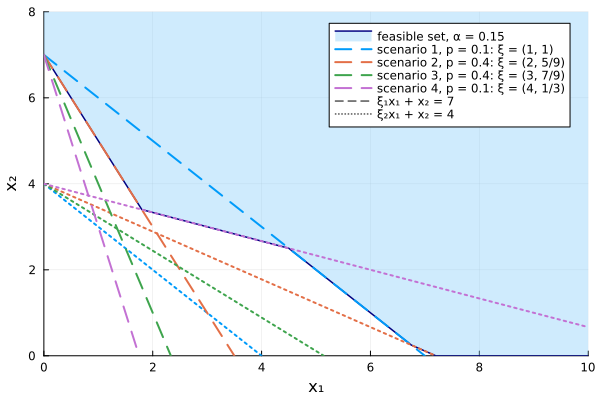

In [4]:
xs = range(0, 10, length = 1001)

function feasible_set_plot()
    fig = plot(xs, boundary.(xs), fillrange = 8, fillalpha = 0.4, fillcolor = :lightskyblue, linecolor = :navy, linewidth = 1.5,
               label = @sprintf("feasible set, α = %.2f", α), xlims = (0, 10), ylims = (0, 8),
               xlabel = "x₁", ylabel = "x₂", legend = :topright)
    for s in 1:S
        color = palette(:default)[s]
        plot!(fig, xs, h[1] .- ξ1[s] .* xs, color = color, linestyle = :dash, linewidth = 2,
              label = @sprintf("scenario %d, p = %.1f: ξ = (%d, %s)", s, p[s], ξ1[s], ξ2_label[s]))
        plot!(fig, xs, h[2] .- ξ2[s] .* xs, color = color, linestyle = :dot, linewidth = 2, label = "")
    end
    plot!(fig, [NaN], [NaN], color = :black, linestyle = :dash, label = "ξ₁x₁ + x₂ = 7")
    plot!(fig, [NaN], [NaN], color = :black, linestyle = :dot, label = "ξ₂x₁ + x₂ = 4")
    return fig
end

fig = feasible_set_plot()
savefig(fig, "../imgs/chance_constraint_feasible_region.pdf")   # figure of the slides
display("image/png", fig)

The feasible set is not convex, although all the constraints are linear: the segment between two feasible points can leave it.

In [5]:
a, b = [1.8, 3.4], [6.75, 0.25]   # two feasible points
m = (a + b)/2
feasible(x) = x[2] >= boundary(x[1]) - 1e-9
println("a feasible: ", feasible(a), ", b feasible: ", feasible(b), ", midpoint ", m, " feasible: ", feasible(m))

a feasible: true

, b feasible: true, midpoint [4.275, 1.825] feasible: false


## Solving by enumeration

Minimizing over a union of polyhedra amounts to minimizing over each of them, with a linear program, and keeping the best solution.

In [6]:
# Minimize x₁ + x₂, with both constraints enforced in the scenarios of scen
function solve_enforced(scen)
    model = Model(HiGHS.Optimizer)
    set_silent(model)
    @variable(model, x[1:2] >= 0)
    @constraint(model, [s in scen], ξ1[s]*x[1] + x[2] >= h[1])
    @constraint(model, [s in scen], ξ2[s]*x[1] + x[2] >= h[2])
    @objective(model, Min, x[1] + x[2])
    optimize!(model)
    return objective_value(model), value.(x)
end

for scen in admissible
    v, x = solve_enforced(scen)
    @printf("scenarios %-14s value %.4f at x = %s\n", string(scen), v, string(round.(x, digits = 4) .+ 0.0))
end

scenarios [1, 2, 3]      value 7.0000 at x = [0.0, 7.0]
scenarios [2, 3, 4]      value 5.2000 at x = [1.8, 3.4]


scenarios [1, 2, 3, 4]   value 7.0000 at x = [0.0, 7.0]


The optimum is $x^* = (1.8, 3.4)$, with value 5.2: scenario 1 is dropped.
Enforcing all the scenarios, the robust solution, costs 7; so does dropping scenario 4 instead, with a whole segment of optimal solutions on the line $x_1 + x_2 = 7$.

## Mixed-integer formulation

With $S$ scenarios, there are up to $2^S$ sets to enumerate.
The standard formulation introduces a binary variable $z_s$ per scenario, equal to 1 if the constraints of scenario $s$ are enforced:
$$
\xi_{1s} x_1 + x_2 \geq 7 z_s, \quad \xi_{2s} x_1 + x_2 \geq 4 z_s, \quad s = 1, \ldots, S, \qquad \sum_{s=1}^S p_s z_s \geq 1 - \alpha, \qquad z \in \{0, 1\}^S.
$$
When $z_s = 0$, the constraints of scenario $s$ reduce to $\xi_s x_1 + x_2 \geq 0$, which always holds as $x \geq 0$ and $\xi \geq 0$: the right-hand side itself serves as "big-M".

In [7]:
# Probability that both constraints hold at x
joint_probability(x) = sum(p[s] for s in 1:S if ξ1[s]*x[1] + x[2] >= h[1] - 1e-9 && ξ2[s]*x[1] + x[2] >= h[2] - 1e-9; init = 0.0)

model = Model(HiGHS.Optimizer)
set_silent(model)
@variable(model, x[1:2] >= 0)
@variable(model, z[1:S], Bin)   # z[s] = 1: both constraints enforced in scenario s
@constraint(model, [s in 1:S], ξ1[s]*x[1] + x[2] >= h[1]*z[s])
@constraint(model, [s in 1:S], ξ2[s]*x[1] + x[2] >= h[2]*z[s])
@constraint(model, dot(p, z) >= 1 - α)
@objective(model, Min, x[1] + x[2])
optimize!(model)

x_joint = value.(x)
@printf("%s: value %.4f at x = %s, enforced scenarios %s, joint probability %.2f\n",
        termination_status(model), objective_value(model), string(round.(x_joint, digits = 4)),
        string(findall(value.(z) .> 0.5)), joint_probability(x_joint))

OPTIMAL: value 5.2000 at x = [1.8, 3.4], enforced scenarios [2, 3, 4], joint probability 0.90


## Separate chance constraints

With separate chance constraints,
$$
P\left[\xi_1 x_1 + x_2 \geq 7\right] \geq 1 - \alpha_1, \qquad P\left[\xi_2 x_1 + x_2 \geq 4\right] \geq 1 - \alpha_2,
$$
each constraint has its own binary variables, and may drop a different scenario.
We take $\alpha_1 = \alpha_2 = \alpha$.

In [8]:
model_sep = Model(HiGHS.Optimizer)
set_silent(model_sep)
@variable(model_sep, x[1:2] >= 0)
@variable(model_sep, z[1:S, 1:2], Bin)   # z[s, i] = 1: constraint i enforced in scenario s
@constraint(model_sep, [s in 1:S], ξ1[s]*x[1] + x[2] >= h[1]*z[s, 1])
@constraint(model_sep, [s in 1:S], ξ2[s]*x[1] + x[2] >= h[2]*z[s, 2])
@constraint(model_sep, [i in 1:2], sum(p[s]*z[s, i] for s in 1:S) >= 1 - α)
@objective(model_sep, Min, x[1] + x[2])
optimize!(model_sep)

x_sep = value.(x)
zs = value.(z) .> 0.5
@printf("%s: value %.4f at x = %s\n", termination_status(model_sep), objective_value(model_sep), string(round.(x_sep, digits = 4)))
@printf("first constraint enforced in scenarios %s, second in scenarios %s\n", string(findall(zs[:, 1])), string(findall(zs[:, 2])))
@printf("joint probability at x_sep: %.2f\n", joint_probability(x_sep))

OPTIMAL: value 4.9231 at x = [2.0769, 2.8462]
first constraint enforced in scenarios [2, 3, 4], second in scenarios [1, 2, 3]


joint probability at x_sep: 0.80


The separate constraints give a lower cost, $64/13 \approx 4.923$ at $(27/13, 37/13)$: the first constraint drops scenario 1, the second drops scenario 4.
Both constraints then hold together only in scenarios 2 and 3, with probability $0.8 < 1 - \alpha$: the separate constraints are less conservative than the joint one.

The last figure gathers the two solutions, the level line of the objective through $x^*$, and the segment that leaves the feasible set.

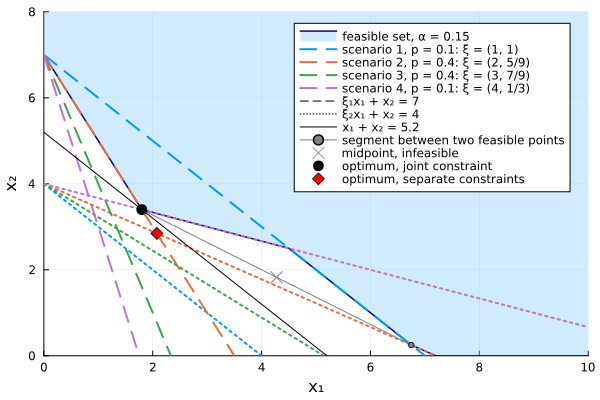

In [9]:
fig2 = feasible_set_plot()
plot!(fig2, xs, objective_value(model) .- xs, color = :black, linewidth = 1, label = "x₁ + x₂ = 5.2")
plot!(fig2, [a[1], b[1]], [a[2], b[2]], color = :gray, linewidth = 1, marker = :circle, markersize = 3, label = "segment between two feasible points")
scatter!(fig2, [m[1]], [m[2]], color = :gray, markershape = :xcross, markersize = 6, label = "midpoint, infeasible")
scatter!(fig2, [x_joint[1]], [x_joint[2]], color = :black, markersize = 6, label = "optimum, joint constraint")
scatter!(fig2, [x_sep[1]], [x_sep[2]], color = :red, markershape = :diamond, markersize = 6, label = "optimum, separate constraints")
display("image/png", fig2)